```{index} single: Pyomo; variables 
```
```{index} single: Pyomo; expressions 
```
```{index} single: Pyomo; objectives 
```
```{index} single: Pyomo; constraints
```
```{index} single: Pyomo; decorators
```
```{index} single: solver; HiGHS
```

# 1.2 A basic Pyomo model

Pyomo is an algebraic modeling language for mathematical optimization that is integrated within the Python programming environment. It enables users to create optimization models consisting of decision variables, expressions, objective functions, and constraints. Pyomo provides tools to transform models, and then solve them using a variety of open-source and commercial solvers. As an open-source project, Pyomo is not tied to any specific vendor, solver, or class of mathematical optimization problems, and is constantly evolving through contributions from third-party developers.

This notebook introduces basic elements of Pyomo common to most applications for the small production planning problem introduced in the [companion notebook](01-production-planning.ipynb):

* [Variables](https://pyomo.readthedocs.io/en/6.8.0/pyomo_modeling_components/Variables.html)
* [Expressions](https://pyomo.readthedocs.io/en/6.8.0/pyomo_modeling_components/Expressions.html)
* [Objectives](https://pyomo.readthedocs.io/en/6.8.0/pyomo_modeling_components/Objectives.html)
* [Constraints](https://pyomo.readthedocs.io/en/6.8.0/pyomo_modeling_components/Constraints.html)
* [SolverFactory](https://pyomo.readthedocs.io/en/6.8.0/solving_pyomo_models.html)

The Pyomo model shown below is a direct translation of the mathematical model into basic Pyomo components. In this approach, parameter values from the mathematical model are included directly in the Pyomo model for simplicity. This method works well for problems with a few decision variables and constraints, but it limits the reuse of the model. Another notebook will demonstrate Pyomo features for writing models for more generic, "data-driven" applications.

We first build and solve the model using Pyomo component constructors. At the end of the notebook, we build the same model using Python decorators and compare the results.

## Preamble: Install Pyomo and a solver

This collection of notebooks is intended to be run in the cloud on [Google Colab](https://colab.google/) or on a personal computer. To meet this goal, we start each notebook by verifying the installation of Pyomo and an appropriate solver. 

When run on Google Colab, an installation of Pyomo and a solver must be done for each new Colab session. The [HiGHS solver](https://highs.dev/) is a high performance open source solver for linear and mixed integer optimization on Google Colab. For a personal computer, we assume Python, Pyomo and the [HiGHS solver](https://highs.dev/) have been previously installed. Note that there are other suitable solvers, both open-source, such as [COIN-OR Cbc solver](https://coin-or.github.io/Cbc/intro.html) and [GLPK](https://www.gnu.org/software/glpk/), and commercial, such as CPLEX, Gurobi, and Mosek.

The following cell sets and verifies a global SOLVER for the notebook. If run on Google Colab, the cell installs Pyomo and the HiGHS solver, while, if run elsewhere, it 
assumes Pyomo and HiGHS have been previously installed. It then sets to use HiGHS as solver via the appsi module and a test is performed to verify that it is available. The solver interface is stored in a global object `SOLVER` for later use.

See [Solvers used in this book](../appendix/installing-pyomo-and-solvers.ipynb) for installation, licensing and the differences between solver interfaces.


In [1]:
import sys
 
if 'google.colab' in sys.modules:
    %pip install pyomo >/dev/null 2>/dev/null
    %pip install highspy >/dev/null 2>/dev/null
 
solver = 'appsi_highs'
 
import pyomo.environ as pyo
SOLVER = pyo.SolverFactory(solver)

assert SOLVER.available(), f"Solver {solver} is not available."

## Step 1. Import Pyomo

The first step for a new Pyomo model is to import the needed components into the Python environment. The module `pyomo.environ` provides the components most commonly used for building Pyomo models. Although this module was imported in the previous code cell, we mention it again here also to emphasize our standardized conventions. Throughout this collection of notebooks, a uniform standard is maintained for importing `pyomo.environ` consistently using the alias `pyo`.

In [2]:
import pyomo.environ as pyo

## Step 2. The `ConcreteModel` object

Pyomo models can be named using any standard Python variable name. In the following code cell, an instance of `ConcreteModel` is created and stored in a Python variable named `model`. It is best to use a short name since it will appear as a prefix for every Pyomo variable and constraint. `ConcreteModel` accepts an optional string argument used to title subsequent reports.

`pyo.ConcreteModel()` is used to create a model object when the problem data is known at the time of construction. Alternatively, pyo.AbstractModel() can create models where the problem data will be provided later to create specific model instances. But this is normally not needed when using the "data-driven" approach demonstrated in this collection of notebooks.


In [3]:
# create model with optional problem title
model = pyo.ConcreteModel("Production Planning: Version 1")

The `.display()` method displays the current content of a Pyomo model. When developing new models, this is a useful tool to verify that the model is being constructed as intended. At this stage, the major components of the model are empty.

In [4]:
# display model
model.display()

Model 'Production Planning: Version 1'

  Variables:
    None

  Objectives:
    None

  Constraints:
    None


## Step 3. Decision variables

Decision variables are created with `pyo.Var()`. Decision variables can be assigned to any valid Python identifier. Here, we assign decision variables to the model instance using the Python 'dot' notation. The variable names are chosen to reflect their names in the mathematical model. 

`pyo.Var()` accepts optional keyword arguments. The most commonly used keyword arguments are:

* `domain` specifies a set of values for a decision variable. By default, the domain is the set of all real numbers. Other commonly used domains are `pyo.NonNegativeReals`, `pyo.NonNegativeIntegers`, and `pyo.Binary`.

* `bounds` is an optional keyword argument to specify a tuple containing values for the lower and upper bounds. It is good modeling practice to specify any known and fixed bounds on the decision variables. `None` can be used as a placeholder if one of the two bounds is unknown. Specifying the bounds as `(0, None)` is equivalent to specifying the domain as `pyo.NonNegativeReals`.

The use of the optional keywords is shown in the following cell. Displaying the model shows that the value of the decision variables is not yet known.

In [5]:
# create decision variables
model.x_M = pyo.Var(bounds=(0, None))
model.x_A = pyo.Var(bounds=(0, 80))
model.x_B = pyo.Var(bounds=(0, 100))

model.y_U = pyo.Var(bounds=(0, 40))
model.y_V = pyo.Var(bounds=(0, None))

# display updated model
model.display()

Model 'Production Planning: Version 1'

  Variables:
    x_M : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  None :  None : False :  True :  Reals
    x_A : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  None :    80 : False :  True :  Reals
    x_B : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  None :   100 : False :  True :  Reals
    y_U : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  None :    40 : False :  True :  Reals
    y_V : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  None :  None : False :  True :  Reals

  Objectives:
    None

  Constraints:
    None


## Step 4. Expressions

Pyomo expressions are mathematical formulas that involve decision variables. The following cell creates named `Expression` components for revenue and cost, assigned to `model.revenue` and `model.cost`. The `expr` keyword supplies each formula. These components can be reused in the objective and displayed with `pprint()`; they do not introduce new decision variables.

In [6]:
# create named expressions
model.revenue = pyo.Expression(expr=270 * model.y_U + 210 * model.y_V)
model.cost = pyo.Expression(expr=10 * model.x_M + 50 * model.x_A + 40 * model.x_B)

model.revenue.pprint()
model.cost.pprint()

revenue : Size=1, Index=None
    Key  : Expression
    None : 270*y_U + 210*y_V
cost : Size=1, Index=None
    Key  : Expression
    None : 10*x_M + 50*x_A + 40*x_B


## Step 5. Objective

The objective for this example is to maximize profit, given by the difference between revenue and cost. We use `pyo.Objective()`, with `expr` supplying the expression to optimize and `sense` specifying maximization.

In [7]:
model.profit = pyo.Objective(expr=model.revenue - model.cost, sense=pyo.maximize)

## Step 6. Constraints

Constraints are logical relationships between expressions that define the range of feasible solutions in an optimization problem. A constraint consists of two expressions separated by one of the logical relationships. The logical relationships can be equality (`==`), less-than (`<=`), or greater-than (`>=`). 

Constraints are created with `pyo.Constraint()`. The `expr` keyword supplies the relationship for each constraint.

In [8]:
model.raw_materials = pyo.Constraint(expr=10 * model.y_U + 9 * model.y_V <= model.x_M)
model.labor_A = pyo.Constraint(expr=1 * model.y_U + 1 * model.y_V <= model.x_A)
model.labor_B = pyo.Constraint(expr=2 * model.y_U + 1 * model.y_V <= model.x_B)

model.pprint()

5 Var Declarations
    x_A : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  None :    80 : False :  True :  Reals
    x_B : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  None :   100 : False :  True :  Reals
    x_M : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  None :  None : False :  True :  Reals
    y_U : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  None :    40 : False :  True :  Reals
    y_V : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  None :  None : False :  True :  Reals

2 Expression Declarations
    cost : Size=1, Index=None
        Key  : Expression
        None : 10*x_M + 50*x_A + 40*x_B
    revenue : Size=1, Index=None
        Key  : Expression
        None : 270*y_U + 210*y_V



## Step 7. Solve the model

With the model now fully specified, the next step is to compute a solution. A solver object is created with `SolverFactory` then applied to the model as shown in the following cell. The optional keyword `tee=True` causes the solver to print its output to the output. This can be useful for debugging problems that arise when developing a new model.

In [9]:
results = SOLVER.solve(model, tee=True)
pyo.assert_optimal_termination(results)

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


LP has 3 rows; 5 cols; 9 nonzeros
Coefficient ranges:
  Matrix  [1e+00, 1e+01]
  Cost    [1e+01, 3e+02]
  Bound   [4e+01, 1e+02]
  RHS     [0e+00, 0e+00]
Presolving model
2 rows, 4 cols, 6 nonzeros 0s
Dependent equations search running on 2 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
2 rows, 4 cols, 6 nonzeros 0s
Presolve reductions: rows 2(-1); columns 4(-1); nonzeros 6(-3) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -2.0999953995e+02 Ph1: 2(4); Du: 3(210) 0.0s
          3    -2.6000000000e+03 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model status        : Optimal
Simplex   iterations: 3
Objective value     :  2.6000000000e+03
P-D objective error :  0.0000000000e+00
HiGHS run time      :          0.00


## Step 8. Reporting the solution

The final step in most applications is to report the solution in a suitable format. For this example, we demonstrate simple tabular and graphic reports using the Pandas library. For an overview of other ways to report and visualize the solutions, see also the appendix of [this notebook](../04/03-gasoline-distribution.ipynb) from Chapter 4.

### Pyomo `pprint()`

Pyomo provides several functions for creating model reports that contain solution values. The `pprint()` method can be applied to the entire model, or to individual components of the model, as shown in the following cells.

In [10]:
# display the whole model
model.pprint()

5 Var Declarations
    x_A : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  80.0 :    80 : False : False :  Reals
    x_B : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 : 100.0 :   100 : False : False :  Reals
    x_M : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 : 740.0 :  None : False : False :  Reals
    y_U : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  20.0 :    40 : False : False :  Reals
    y_V : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  60.0 :  None : False : False :  Reals

2 Expression Declarations
    cost : Size=1, Index=None
        Key  : Expression
        None : 10*x_M + 50*x_A + 40*x_B
    revenue : Size=1, Index=None
        Key  : Expression
        None : 270*y_U + 210*y_V



In [11]:
# display a component of the model
model.profit.pprint()

profit : Size=1, Index=None, Active=True
    Key  : Active : Sense    : Expression
    None :   True : maximize : (270*y_U + 210*y_V) - (10*x_M + 50*x_A + 40*x_B)


### Accessing solution values with `pyo.value()`

After a solution to a Pyomo model has been successfully computed, values for the objective, expressions, and decisions variables can be accessed with `pyo.value()`.

In [12]:
pyo.value(model.profit)

2600.0

When combined with [Python f strings](https://docs.python.org/3/tutorial/inputoutput.html), `pyo.value()` provides a convenient means of creating formatted reports.

In [13]:
print(f" Profit = {pyo.value(model.profit): 9.2f}")
print(f"Revenue = {pyo.value(model.revenue): 9.2f}")
print(f"   Cost = {pyo.value(model.cost): 9.2f}")

 Profit =   2600.00
Revenue =  18000.00
   Cost =  15400.00


Pyomo also provides a shortcut for accessing solution values: variable objects are callable, so `model.x_A()` returns the current value of `model.x_A`. Solving the model assigns values to its variables; it does not create new Python functions.

In [14]:
print("x_A =", model.x_A())
print("x_B =", model.x_B())
print("x_M =", model.x_M())

x_A = 80.0
x_B = 100.0
x_M = 740.0


### Creating reports with pandas

Pandas is an open-source library for working with data in Python and is widely used in the data science community. Here we use a Pandas `Series()` object to hold and display solution data. We can then visualize them using the Matplotlib library, for instance with a bar chart.

In [15]:
import pandas as pd

# create pandas series for production and raw materials
production = pd.Series(
    {
        "U": pyo.value(model.y_U),
        "V": pyo.value(model.y_V),
    }
)

raw_materials = pd.Series(
    {
        "A": pyo.value(model.x_A),
        "B": pyo.value(model.x_B),
        "M": pyo.value(model.x_M),
    }
)

# display pandas series
display(production)
display(raw_materials)

U    20.0
V    60.0
dtype: float64

A     80.0
B    100.0
M    740.0
dtype: float64

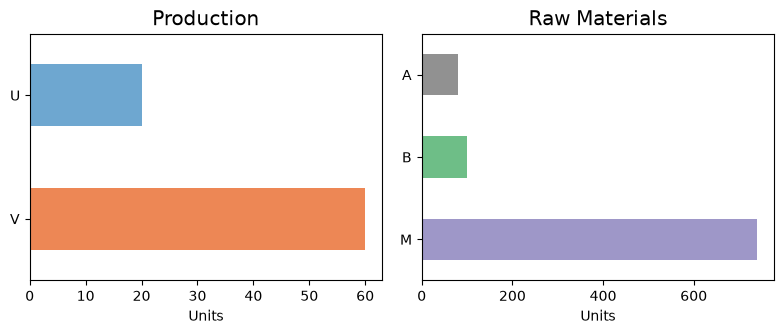

In [16]:
import matplotlib.pyplot as plt

# Create a 1x2 grid of subplots and configure global settings
fig, ax = plt.subplots(1, 2, figsize=(8, 3.5))
plt.rcParams["font.size"] = 12
colors = plt.cm.tab20c.colors
color_sets = [[colors[0], colors[4]], [colors[16], colors[8], colors[12]]]
datasets = [production, raw_materials]
titles = ["Production", "Raw Materials"]

# Plot data on subplots
for i, (data, title, color_set) in enumerate(zip(datasets, titles, color_sets)):
    data.plot(ax=ax[i], kind="barh", title=title, alpha=0.7, color=color_set)
    ax[i].set_xlabel("Units")
    ax[i].invert_yaxis()
plt.tight_layout()
plt.show()

<a name="the-same-model-with-decorators"></a>

## The same model with decorators

The main example used constructors such as `pyo.Expression(expr=...)`. A [Python decorator](https://peps.python.org/pep-0318/) is written immediately above a function definition. Pyomo uses this notation to create a model component from the function below it:

```python
@decorated_model.Expression()
def revenue(m):
    return 270 * m.y_U + 210 * m.y_V
```

Here is how to read these three lines:

| Part | Meaning |
| :--- | :--- |
| `@decorated_model.Expression()` | Create an `Expression` on `decorated_model`. |
| `def revenue(m):` | Use the function name for the component name, `decorated_model.revenue`. Pyomo passes the model as `m`. |
| `return ...` | Supply the symbolic expression used to construct the component. |

For this `ConcreteModel`, Pyomo calls the function when the component is constructed. The function returns an expression involving variables, before their solution values are known. It is a construction rule, not the optimization algorithm.

The same pattern applies to `Objective` and `Constraint`. An objective rule returns the expression to optimize, with `sense` selecting maximization or minimization; a constraint rule returns a relationship such as `<=`. Using a decorator supplies the rule and attaches the component under the function's name, instead of writing a separate constructor assignment.

We now create a separate model so that the first model remains available for comparison. The variables, bounds and formulas are unchanged.

In [17]:
decorated_model = pyo.ConcreteModel("Production Planning: Decorator version")

decorated_model.x_M = pyo.Var(bounds=(0, None))
decorated_model.x_A = pyo.Var(bounds=(0, 80))
decorated_model.x_B = pyo.Var(bounds=(0, 100))
decorated_model.y_U = pyo.Var(bounds=(0, 40))
decorated_model.y_V = pyo.Var(bounds=(0, None))


@decorated_model.Expression()
def revenue(m):
    return 270 * m.y_U + 210 * m.y_V


@decorated_model.Expression()
def cost(m):
    return 10 * m.x_M + 50 * m.x_A + 40 * m.x_B


@decorated_model.Objective(sense=pyo.maximize)
def profit(m):
    return m.revenue - m.cost


@decorated_model.Constraint()
def raw_materials(m):
    return 10 * m.y_U + 9 * m.y_V <= m.x_M


@decorated_model.Constraint()
def labor_A(m):
    return 1 * m.y_U + 1 * m.y_V <= m.x_A


@decorated_model.Constraint()
def labor_B(m):
    return 2 * m.y_U + 1 * m.y_V <= m.x_B


decorated_model.revenue.pprint()
decorated_model.cost.pprint()

revenue : Size=1, Index=None
    Key  : Expression
    None : 270*y_U + 210*y_V
cost : Size=1, Index=None
    Key  : Expression
    None : 10*x_M + 50*x_A + 40*x_B


Both styles construct the same optimization problem. Solving the second model gives the same production plan, resource use and profit for these data. The table compares all five variables and the revenue, cost and profit. More generally, equivalent models can have different optimal plans when there are alternative optima.

In [18]:
decorated_results = SOLVER.solve(decorated_model)
pyo.assert_optimal_termination(decorated_results)

names = ["y_U", "y_V", "x_M", "x_A", "x_B", "revenue", "cost", "profit"]
comparison = pd.DataFrame(
    {
        "Constructors": [pyo.value(getattr(model, name)) for name in names],
        "Decorators": [pyo.value(getattr(decorated_model, name)) for name in names],
    },
    index=names,
)
assert (abs(comparison["Constructors"] - comparison["Decorators"]) < 1e-7).all()
display(comparison)

,Constructors,Decorators
y_U,20.0,20.0
y_V,60.0,60.0
x_M,740.0,740.0
x_A,80.0,80.0
x_B,100.0,100.0
revenue,18000.0,18000.0
cost,15400.0,15400.0
profit,2600.0,2600.0


To discover more advanced Pyomo features, see the [next notebook](03-production-planning-advanced.ipynb).